# Proyek Klasifikasi Gambar: Land-Use Scene Classification
- **Nama:** Rifky Rais Maselino
- **Email:** rifkyrais@gmail.com
- **ID Dicoding:** maseonil

**Link**: https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification

## Import Semua Packages/Library yang Digunakan

In [1]:
!pip install tensorflowjs -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 23.2 which is incompatible.
db-dtypes 1.5.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
google-cloud-bigquery 3.40.1 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.


In [2]:
import tensorflow as tf                                                                   # Kebutuhan klasifikasi gambar
import numpy as np                                                                        # Operasi matematika untuk gambar
from google.colab import files                                                            # Upload file untuk extract dataset
import os, random, shutil                                                                 # Manajemen direktori dan set random
from sklearn.model_selection import train_test_split                                      # Split dataset secara manual
from PIL import Image                                                                     # Memeriksa keragaman resolusi gambar
import matplotlib.pyplot as plt                                                           # Plot gambar serta visualisasi evaluasi model
from tensorflow.keras.utils import image_dataset_from_directory                           # Preprocessing gambar
from tensorflow.keras import layers, models, Sequential, optimizers, losses               # Set layer, model, sequential, optimizer, dan loss
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input                # Set preprocess input dari EfficientNetV2B0
from tensorflow.keras.backend import clear_session                                        # Clear session
from tensorflow.keras.applications import EfficientNetV2B0                                # Set Transfer learning
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint  # Set callback ketika training model
from sklearn.metrics import classification_report, confusion_matrix                       # Evaluasi Model
import seaborn as sns                                                                     # Plot Confusion Matrix
from tensorflow.keras.preprocessing import image                                          # Inferensi Model

In [3]:
# Set seed untuk menjaga konsistensi data serta set image size, batch size, dan autotune untuk preprocessing gambar
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

## Data Preparation

### Data Loading

In [4]:
# Uoload dataset kaggle dengan generate token dan generate API key dari kaggle
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"maseonil","key":"beaf8e787abd3f24f6f1722352be4825"}'}

In [5]:
# Mengambil dataset kaggle dari website
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d apollo2506/landuse-scene-classification
!unzip -q landuse-scene-classification.zip

Dataset URL: https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification
License(s): CC0-1.0
100% 1.98G/1.98G [00:13<00:00, 254MB/s]
100% 1.98G/1.98G [00:13<00:00, 160MB/s]


In [6]:
# Mengambil dataset dari file colab
landuse_dataset = '/content/images'

### Data Preprocessing

#### Split Dataset

In [7]:
# Membagi dataset menjadi 80% data latih 10% data validasi dan 10% data uji lalu disimpan ke folder masing-masing
split_dir = "/content/split_dataset"
for folder in ["train", "val", "test"]:
    path = os.path.join(split_dir, folder)
    if not os.path.exists(path):
        os.makedirs(path)

classes = os.listdir(landuse_dataset)
for cls in classes:
    cls_path = os.path.join(landuse_dataset, cls)
    images = os.listdir(cls_path)
    random.shuffle(images)
    train_files, temp_files = train_test_split(images, test_size=0.2, random_state=42)
    val_files, test_files = train_test_split(temp_files, test_size=0.5, random_state=42)
    for split, files in zip(["train","val","test"], [train_files, val_files, test_files]):
        split_cls_path = os.path.join(split_dir, split, cls)
        os.makedirs(split_cls_path, exist_ok=True)
        for f in files:
            shutil.copy(os.path.join(cls_path, f), os.path.join(split_cls_path, f))

In [8]:
# Deklarasi folder train, val, dan test untuk preprocessing dan augmentasi data
train = '/content/split_dataset/train'
val  = '/content/split_dataset/val'
test = '/content/split_dataset/test'

In [9]:
# Memeriksa keragaman resolusi gambar di dataset
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0

    for subdir in os.listdir(directory):
        subdir_path = os.path.join(directory, subdir)
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images}")
        total_images += num_images

        for img_file in image_files:
            img_path = os.path.join(subdir_path, img_file)
            with Image.open(img_path) as img:
                unique_sizes.add(img.size)

        for size in unique_sizes:
            print(f"- {size}")
        print("---------------")

    print(f"\nTotal: {total_images}")

print_images_resolution(landuse_dataset)

mobilehomepark: 500
- (253, 256)
- (256, 253)
- (256, 256)
---------------
freeway: 500
- (253, 256)
- (256, 253)
- (256, 256)
---------------
sparseresidential: 500
- (255, 256)
- (250, 256)
- (253, 256)
- (242, 256)
- (256, 253)
- (256, 256)
---------------
beach: 500
- (252, 256)
- (255, 256)
- (250, 256)
- (253, 256)
- (242, 256)
- (256, 253)
- (256, 256)
---------------
runway: 500
- (252, 256)
- (255, 256)
- (250, 256)
- (256, 254)
- (253, 256)
- (242, 256)
- (254, 256)
- (256, 253)
- (256, 256)
---------------
chaparral: 500
- (252, 256)
- (255, 256)
- (250, 256)
- (256, 254)
- (253, 256)
- (242, 256)
- (254, 256)
- (256, 253)
- (256, 256)
---------------
tenniscourt: 500
- (252, 256)
- (255, 256)
- (250, 256)
- (256, 254)
- (247, 256)
- (253, 256)
- (242, 256)
- (254, 256)
- (256, 253)
- (256, 256)
---------------
harbor: 500
- (252, 256)
- (257, 257)
- (255, 256)
- (250, 256)
- (256, 254)
- (247, 256)
- (253, 256)
- (242, 256)
- (254, 256)
- (256, 253)
- (256, 256)
-----------

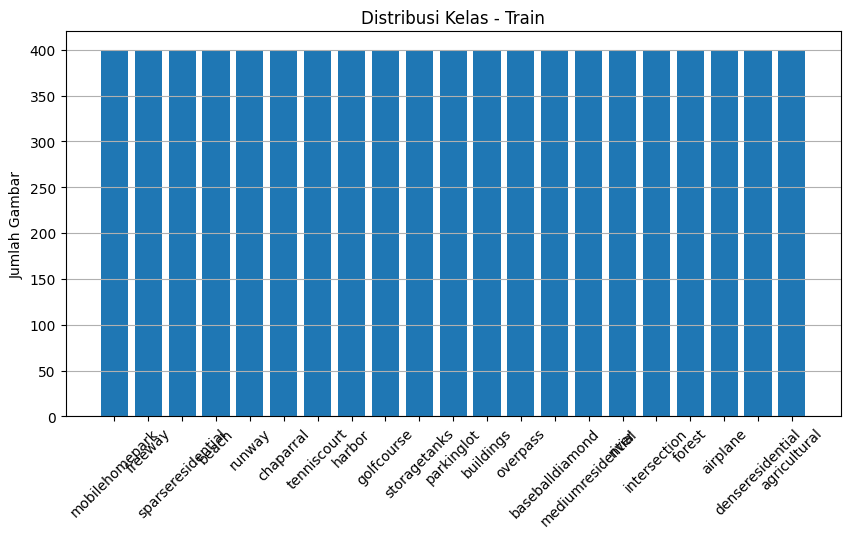

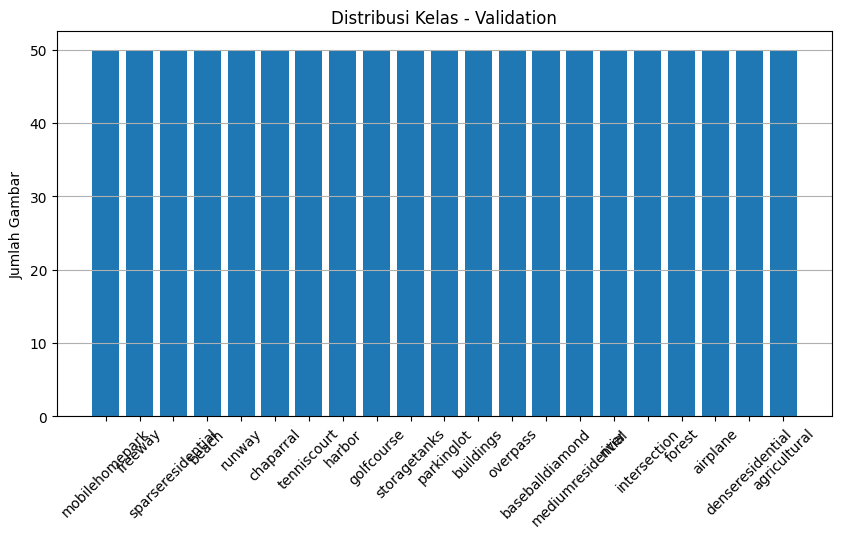

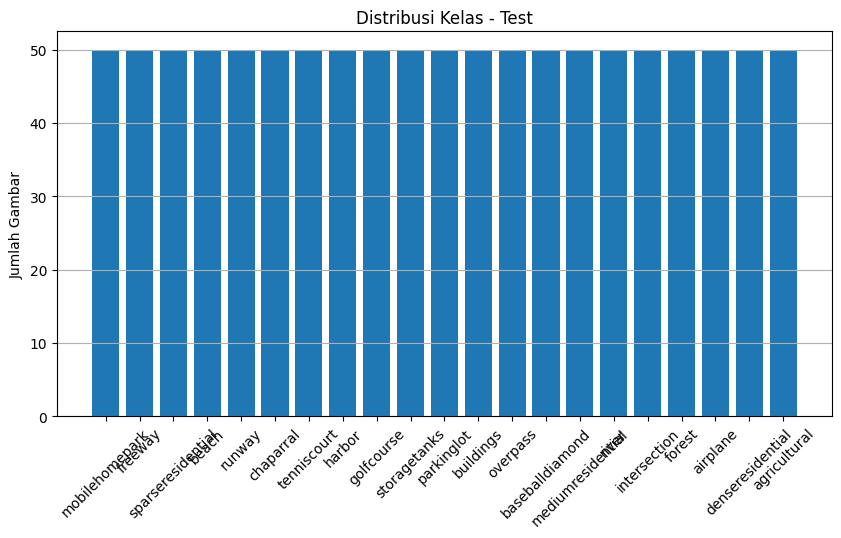

In [10]:
# Visualisasi jumlah gambar berdasarkan label dan data
def plot_class_distribution(directory, title):
    classes = os.listdir(directory)
    counts = {cls: len(os.listdir(os.path.join(directory, cls))) for cls in classes}

    plt.figure(figsize=(10,5))
    plt.bar(counts.keys(), counts.values())
    plt.xticks(rotation=45)
    plt.title(title)
    plt.ylabel("Jumlah Gambar")
    plt.grid(axis='y')
    plt.show()

plot_class_distribution(train, "Distribusi Kelas - Train")
plot_class_distribution(val, "Distribusi Kelas - Validation")
plot_class_distribution(test, "Distribusi Kelas - Test")

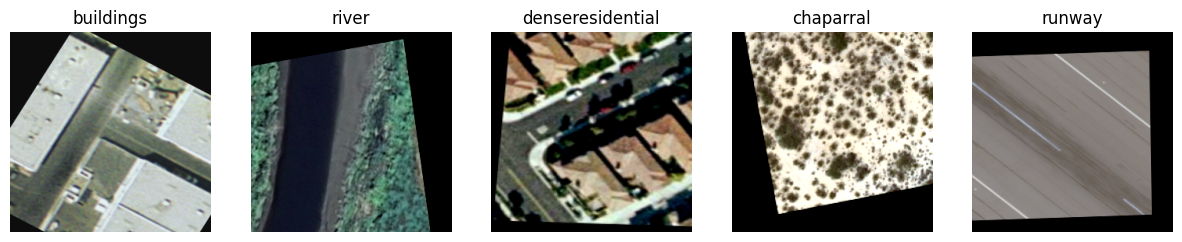

In [11]:
# Menampilkan gambar dan label dari data train
def show_sample_images(directory, num_images=5):
    classes = os.listdir(directory)
    plt.figure(figsize=(15,4))
    for i in range(num_images):
        cls = random.choice(classes)
        img_name = random.choice(os.listdir(os.path.join(directory, cls)))
        img_path = os.path.join(directory, cls, img_name)
        img = plt.imread(img_path)
        plt.subplot(1, num_images, i+1)
        plt.imshow(img)
        plt.title(cls)
        plt.axis('off')
    plt.show()

show_sample_images(train)

In [12]:
# Augmentasi data train serta preprocessing data train, data validation, dan data test
train_ds = image_dataset_from_directory(
    train,
    labels='inferred',
    label_mode='categorical',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = image_dataset_from_directory(
    val,
    labels='inferred',
    label_mode='categorical',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = image_dataset_from_directory(
    test,
    labels='inferred',
    label_mode='categorical',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

num_classes = train_ds.element_spec[1].shape[-1]
class_names = train_ds.class_names

Found 8400 files belonging to 21 classes.
Found 1050 files belonging to 21 classes.
Found 1050 files belonging to 21 classes.


In [13]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1),
])

In [14]:
def preprocess_train(image, label):
    image = data_augmentation(image, training=True)
    image = preprocess_input(image)
    return image, label

def preprocess_eval(image, label):
    image = preprocess_input(image)
    return image, label

train_ds = train_ds.map(preprocess_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_ds.map(preprocess_eval, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds  = test_ds.map(preprocess_eval, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

## Modelling

In [15]:
# Menyusun model klasifikasi gambar data EuroSat dengan Transfer Learning EfficientNetV2B0, layer Conv2D, dan layer MaxPooling2D
clear_session()
base_model = EfficientNetV2B0(
    input_shape=(*IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model = Sequential([
    base_model,
    layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax', dtype='float32')])

model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-b0 (Functional)  │ (None, 8, 8, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 8, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │         5,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,941,925 (34.11 MB)

 Trainable params: 3,021,589 (11.53 MB)

 Non-trainable params: 5,920,336 (22.58 MB)

In [16]:
# Training model data Land-Use
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=2),
    ModelCheckpoint("best_model.keras", monitor='val_accuracy', save_best_only=True, verbose=2),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6, verbose=2)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/20

Epoch 1: val_accuracy improved from -inf to 0.94000, saving model to best_model.keras
132/132 - 213s - 2s/step - accuracy: 0.8267 - loss: 0.9221 - val_accuracy: 0.9400 - val_loss: 0.6265 - learning_rate: 1.0000e-03
Epoch 2/20

Epoch 2: val_accuracy improved from 0.94000 to 0.96571, saving model to best_model.keras
132/132 - 134s - 1s/step - accuracy: 0.9192 - loss: 0.6487 - val_accuracy: 0.9657 - val_loss: 0.5470 - learning_rate: 1.0000e-03
Epoch 3/20

Epoch 3: val_accuracy improved from 0.96571 to 0.97143, saving model to best_model.keras
132/132 - 134s - 1s/step - accuracy: 0.9464 - loss: 0.5688 - val_accuracy: 0.9714 - val_loss: 0.5017 - learning_rate: 1.0000e-03
Epoch 4/20

Epoch 4: val_accuracy improved from 0.97143 to 0.98476, saving model to best_model.keras
132/132 - 141s - 1s/step - accuracy: 0.9608 - loss: 0.5330 - val_accuracy: 0.9848 - val_loss: 0.4726 - learning_rate: 1.0000e-03
Epoch 5/20

Epoch 5: val_accuracy did not improve from 0.98476
132/132 - 132s - 1s/

## Evaluasi dan Visualisasi

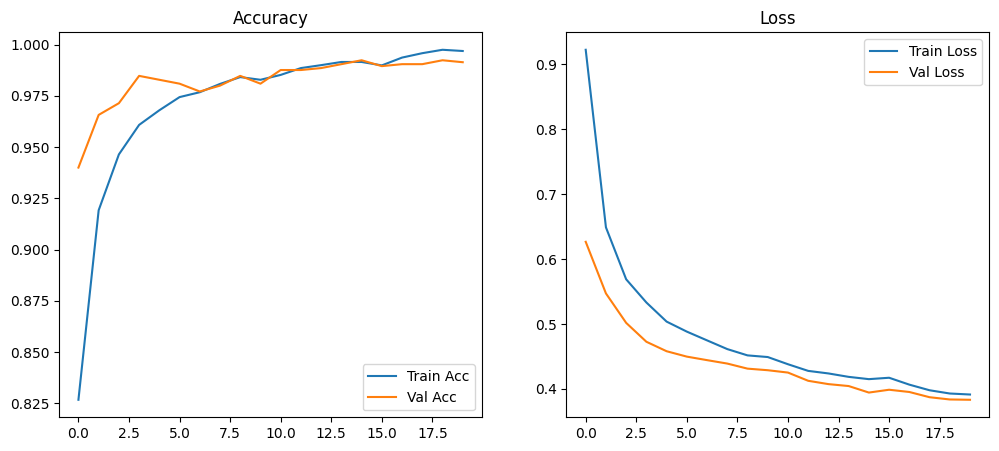

In [17]:
# Plot akurasi dan loss data train dan data validation
def plot_history(history):
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(history.history["accuracy"], label="Train Acc")
    plt.plot(history.history["val_accuracy"], label="Val Acc")
    plt.legend()
    plt.title("Accuracy")

    plt.subplot(1,2,2)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.legend()
    plt.title("Loss")

    plt.show()

plot_history(history)

17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 601ms/step
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        50
         airplane       1.00      0.98      0.99        50
  baseballdiamond       1.00      1.00      1.00        50
            beach       1.00      1.00      1.00        50
        buildings       0.98      0.98      0.98        50
        chaparral       1.00      1.00      1.00        50
 denseresidential       0.98      0.94      0.96        50
           forest       0.98      1.00      0.99        50
          freeway       0.98      0.98      0.98        50
       golfcourse       1.00      1.00      1.00        50
           harbor       1.00      1.00      1.00        50
     intersection       1.00      1.00      1.00        50
mediumresidential       0.94      0.98      0.96        50
   mobilehomepark       1.00      1.00      1.00        50
         overpass       1.00      0.98      0.99        50
       parkin

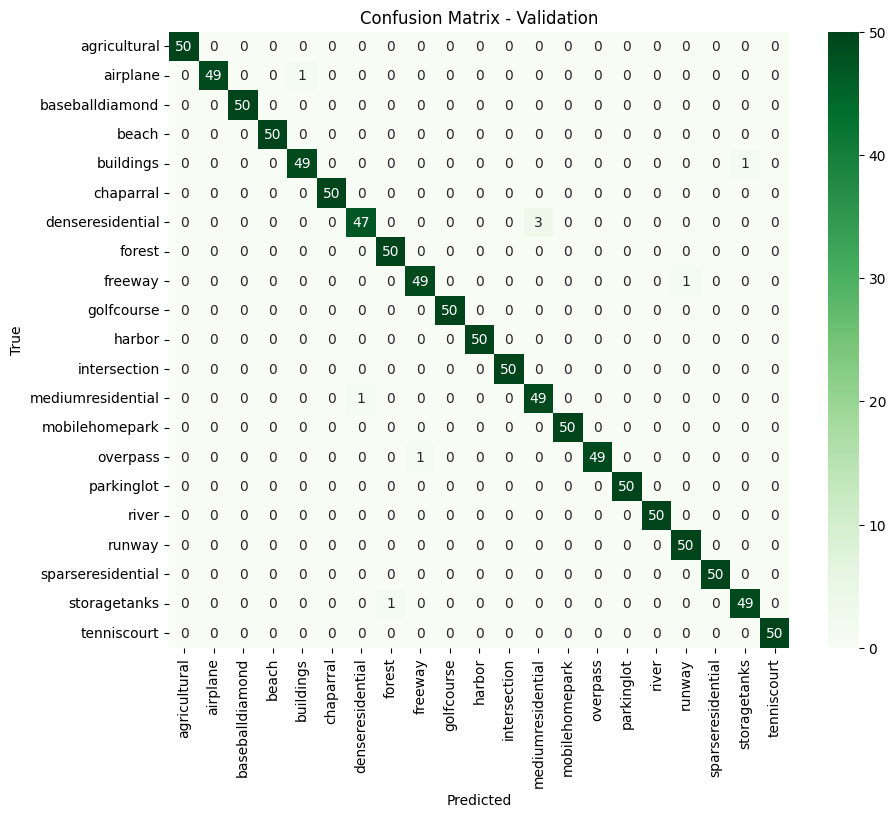

In [18]:
# Evaluasi model pada data validation menggunakan classification report dan confusion matrix
y_pred_val = np.argmax(model.predict(val_ds), axis=1)

y_true_val = np.concatenate([y for _, y in val_ds], axis=0)
y_true_val = np.argmax(y_true_val, axis=1)

print(classification_report(y_true_val, y_pred_val, target_names=class_names))

cm = confusion_matrix(y_true_val, y_pred_val)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - Validation")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        50
         airplane       1.00      1.00      1.00        50
  baseballdiamond       0.98      1.00      0.99        50
            beach       1.00      1.00      1.00        50
        buildings       1.00      1.00      1.00        50
        chaparral       1.00      0.98      0.99        50
 denseresidential       1.00      0.98      0.99        50
           forest       0.98      1.00      0.99        50
          freeway       0.98      1.00      0.99        50
       golfcourse       1.00      1.00      1.00        50
           harbor       1.00      1.00      1.00        50
     intersection       1.00      1.00      1.00        50
mediumresidential       0.98      1.00      0.99        50
   mobilehomepark       1.00      1.00      1.00        50
         overpass       1.00      0.98      0.99        50
       parking

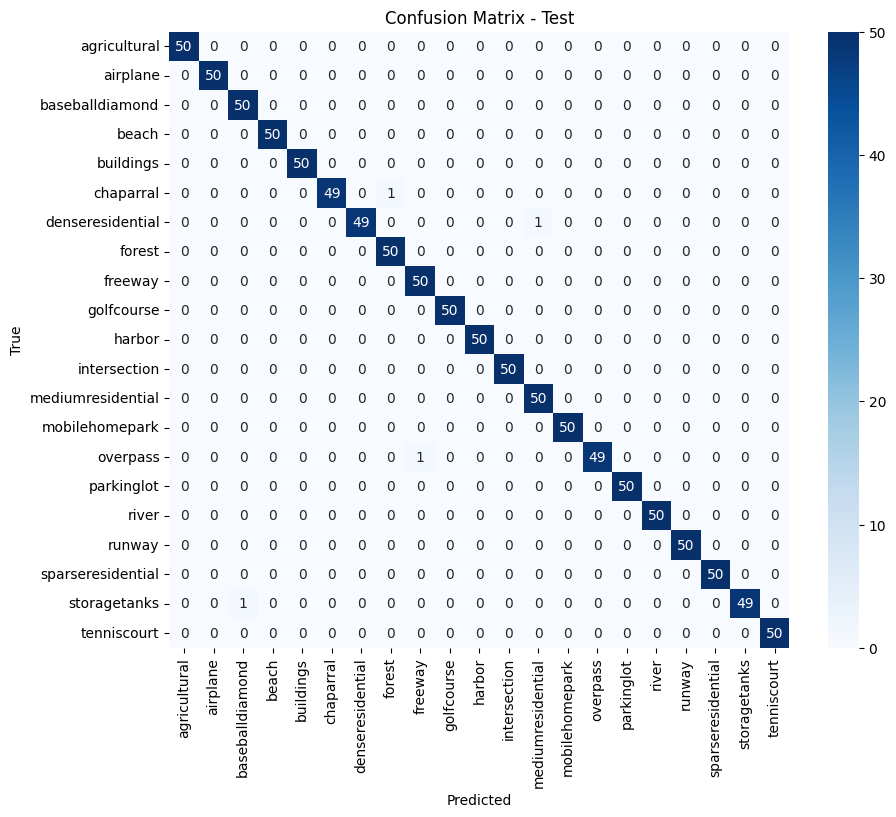

In [19]:
# Evaluasi model pada data test menggunakan classification report dan confusion matrix
y_pred_test = np.argmax(model.predict(test_ds), axis=1)

y_true_test = np.concatenate([y for _, y in test_ds], axis=0)
y_true_test = np.argmax(y_true_test, axis=1)

print(classification_report(y_true_test, y_pred_test, target_names=class_names))

cm = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - Test")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

## Konversi Model

In [20]:
# Menyimpan model dalam format SavedModel
%%capture
model_final = models.load_model("best_model.keras")
model_final.export("saved_model")

In [21]:
# Menyimpan model dalam format TFJS
!tensorflowjs_converter --input_format=tf_saved_model saved_model tfjs_model

2026-03-07 04:39:04.315716: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772858344.338699   14958 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772858344.345434   14958 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772858344.362044   14958 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772858344.362067   14958 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772858344.362070   14958 computation_placer.cc:177] computation placer alr

In [22]:
# Menyimpan model dalam format TF-Lite
converter = tf.lite.TFLiteConverter.from_saved_model("saved_model")
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

tflite_model = converter.convert()

with open("model.tflite", "wb") as f:
    f.write(tflite_model)

## Inference (Optional)

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


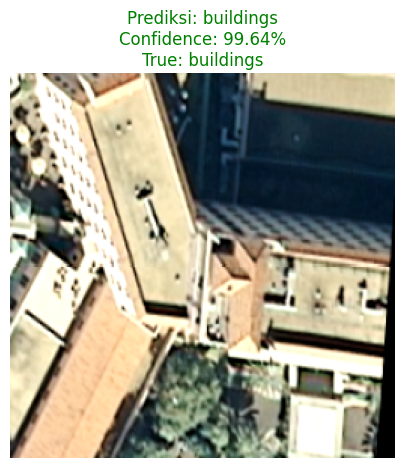

In [23]:
# Inferensi gambar acak di folder test menggunakan model berformat TF-Lite
interpreter = tf.lite.Interpreter(model_path="/content/model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
IMG_SIZE = input_details[0]['shape'][1]

class_folder = random.choice(os.listdir(test))
img_name = random.choice(os.listdir(os.path.join(test, class_folder)))
img_path = os.path.join(test, class_folder, img_name)

img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

interpreter.set_tensor(input_details[0]['index'], img_array)
interpreter.invoke()
output = interpreter.get_tensor(output_details[0]['index'])[0]

pred_idx = np.argmax(output)
confidence = output[pred_idx]
pred_class = class_names[pred_idx]

title_color = "green" if pred_class == class_folder else "red"

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Prediksi: {pred_class}\nConfidence: {confidence:.2%}\nTrue: {class_folder}", color=title_color)
plt.axis("off")
plt.show()

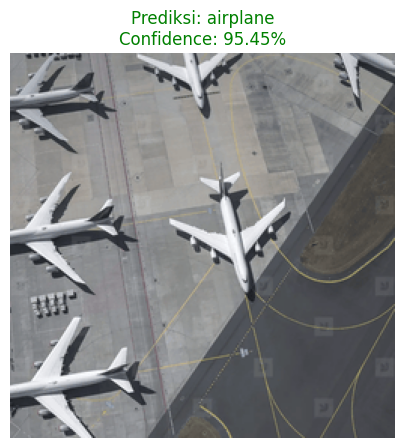

In [24]:
# Inferensi gambar di luar dataset menggunakan model berformat TF-Lite
img_path_real = '/content/airport.png'

img_real = image.load_img(img_path_real, target_size=(IMG_SIZE, IMG_SIZE))
img_array_real = image.img_to_array(img_real)
img_array_real = preprocess_input(img_array_real)
img_array_real = np.expand_dims(img_array_real, axis=0)

interpreter.set_tensor(input_details[0]['index'], img_array_real)
interpreter.invoke()
output_real = interpreter.get_tensor(output_details[0]['index'])[0]

pred_index_real = np.argmax(output_real)
confidence_real = output_real[pred_index_real]
pred_label_real = class_names[pred_index_real]

color = "green" if confidence_real >= 0.5 else "red"

plt.figure(figsize=(5, 5))
plt.imshow(img_real)
plt.title(f"Prediksi: {pred_label_real}\nConfidence: {confidence_real:.2%}", color=color)
plt.axis('off')
plt.show()